In [1]:
import numpy as np

slotratio_by_step = np.array([
    # 0 番のスロットマシンのデータ
    [ 
        [ 1.0, 1.0, 0.5, 0.5, 0.5 ], # エピソード 0 のデータ
        [ 0.0, 0.0, 1.0, 0.5, 0.5 ], # エピソード 1 のデータ
        [ 0.0, 0.0, 0.0, 0.0, 0.0 ], # エピソード 2 のデータ
    ],
    # 1 番のスロットマシンのデータ
    [ 
        [ 0.0, 1.0, 1.0, 1.0, 1.0 ], # エピソード 0 のデータ
        [ 0.0, 0.0, 0.0, 0.0, 0.0 ], # エピソード 1 のデータ
        [ 0.0, 0.0, 1.0, 1.0, 1.0 ], # エピソード 2 のデータ
    ],
    # 2 番のスロットマシンのデータ
    [ 
        [ 0.0, 0.0, 0.0, 1.0, 1.0 ], # エピソード 0 のデータ
        [ 1.0, 1.0, 1.0, 1.0, 0.5 ], # エピソード 1 のデータ
        [ 0.0, 1.0, 1.0, 1.0, 1.0 ], # エピソード 2 のデータ
    ],
])  

In [2]:
max_ratio = np.max(slotratio_by_step, axis=0)
best_estimated_arm = slotratio_by_step == max_ratio
print(best_estimated_arm)

[[[ True  True False False False]
  [False False  True False  True]
  [ True False False False False]]

 [[False  True  True  True  True]
  [False False False False False]
  [ True False  True  True  True]]

 [[False False False  True  True]
  [ True  True  True  True  True]
  [ True  True  True  True  True]]]


In [3]:
p = [0.3, 0.5, 0.7]
bestarm = np.argmax(p)
print(bestarm)

2


In [4]:
accuracy_by_step = []
armnum = 3
episodenum = 3
stepnum = 5
for s in range(stepnum):
    correct_count = 0
    for e in range(episodenum):
        is_correct = True
        for a in range(armnum):
            if (a == bestarm and (not best_estimated_arm[a][e][s])) or \
               (a != bestarm and best_estimated_arm[a][e][s]):
                is_correct = False
                break
        if is_correct:
            correct_count += 1
    accuracy_by_step.append(correct_count / episodenum)
print(accuracy_by_step)

[0.3333333333333333, 0.6666666666666666, 0.0, 0.3333333333333333, 0.0]


In [5]:
best_estimated_armnum = np.sum(best_estimated_arm, axis=0)
print(best_estimated_armnum)

[[1 2 1 2 2]
 [1 1 2 1 2]
 [3 1 2 2 2]]


In [6]:
best_estimated_armnum_is_one = (best_estimated_armnum == 1)
print(best_estimated_armnum_is_one)

[[ True False  True False False]
 [ True  True False  True False]
 [False  True False False False]]


In [7]:
is_correct = (best_estimated_arm[bestarm] & best_estimated_armnum_is_one)
print(is_correct)

[[False False False False False]
 [ True  True False  True False]
 [False  True False False False]]


In [8]:
accuracy = np.sum(is_correct, axis=0) / episodenum
print(accuracy)

[0.33333333 0.66666667 0.         0.33333333 0.        ]


In [9]:
# 手順 1
max_ratio = np.max(slotratio_by_step, axis=0)
# 手順 2
best_estimated_arm = slotratio_by_step == max_ratio
# 手順 3
best_estimated_armnum = np.sum(best_estimated_arm, axis=0)
best_estimated_armnum_is_one = (best_estimated_armnum == 1)
is_correct = (best_estimated_arm[bestarm] & best_estimated_armnum_is_one)
accuracy = np.sum(is_correct, axis=0) / episodenum
print(accuracy)

[0.33333333 0.66666667 0.         0.33333333 0.        ]


In [10]:
from ai import MAB_Agent

def calc_accuracy_by_step(self):
    bestarm = np.argmax(self.mab.p)
    max_ratio = np.max(self.slotratio_by_step, axis=0)
    best_estimated_arm = self.slotratio_by_step == max_ratio
    best_estimated_armnum = np.sum(best_estimated_arm, axis=0)
    best_estimated_armnum_is_one = (best_estimated_armnum == 1)
    is_correct = (best_estimated_arm[bestarm] & best_estimated_armnum_is_one)
    self.accuracy_by_step = np.sum(is_correct, axis=0) / self.episodenum
    
MAB_Agent.calc_accuracy_by_step = calc_accuracy_by_step

In [11]:
egreedy_agents = []
for i in range(31):
    epsilon = i / 100
    egreedy_agent = MAB_Agent.load(f"../data/egreedy_agent(e={epsilon},step=1000)")
    egreedy_agents.append(egreedy_agent)

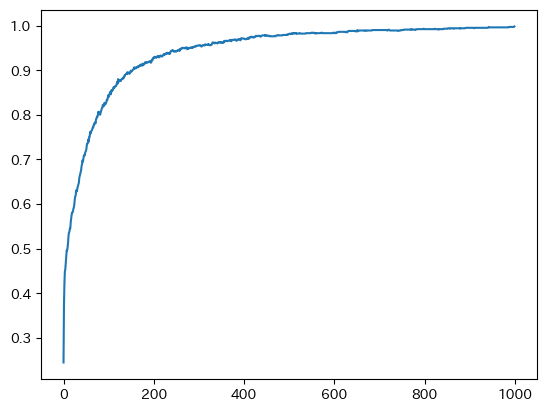

In [12]:
import matplotlib.pyplot as plt

egreedy_agents[10].calc_accuracy_by_step()
plt.plot(egreedy_agents[10].accuracy_by_step)

In [13]:
def draw_accuracy_by_step(self, miny=0, maxy=1):
    self.calc_accuracy_by_step()
    plt.title(f"{self.title}\n判定精度の推移（{self.episodenum} エピソード）")
    plt.plot(self.accuracy_by_step)
    plt.ylim(miny, maxy)
    plt.xlabel("ステップ数")
    plt.ylabel("判定精度")
    plt.show()      
    
MAB_Agent.draw_accuracy_by_step = draw_accuracy_by_step

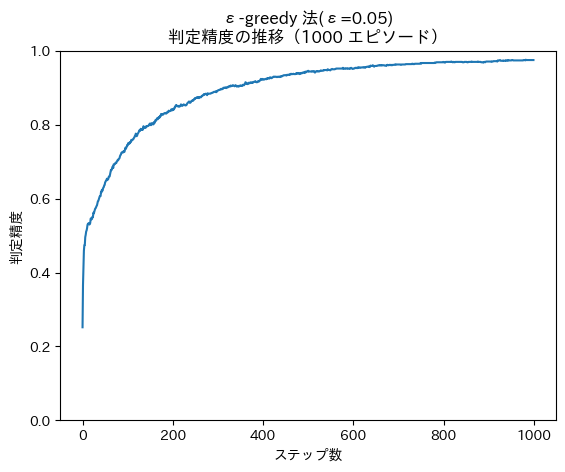

In [14]:
egreedy_agents[5].draw_accuracy_by_step()

In [15]:
@staticmethod
def compare_accuracy_by_step(agent_list, miny=0, maxy=1):
    plt.title(f"判定精度の推移の比較（{agent_list[0].episodenum} エピソード）")
    for agent in agent_list:
        agent.calc_accuracy_by_step()
        plt.plot(agent.accuracy_by_step, label=agent.title)
    plt.ylim(miny, maxy)
    plt.xlabel("ステップ数")
    plt.ylabel("判定精度")
    plt.legend()
    plt.show() 
    
MAB_Agent.compare_accuracy_by_step = compare_accuracy_by_step

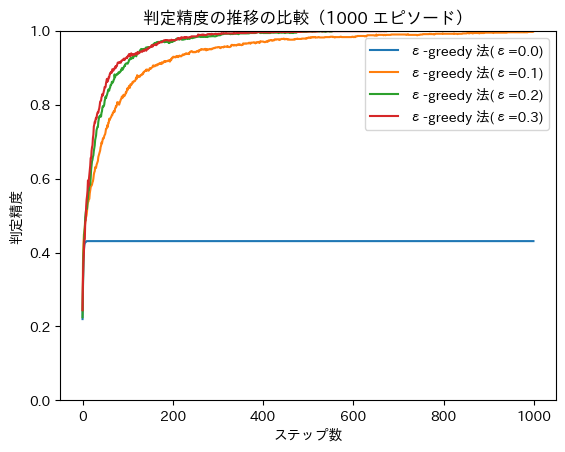

In [16]:
MAB_Agent.compare_accuracy_by_step(egreedy_agents[::10])

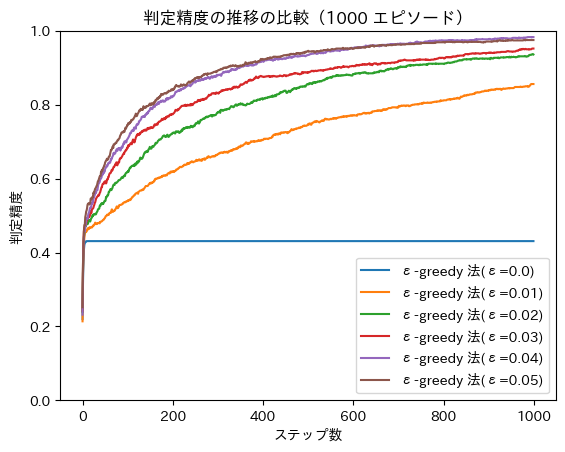

In [17]:
MAB_Agent.compare_accuracy_by_step(egreedy_agents[:6])

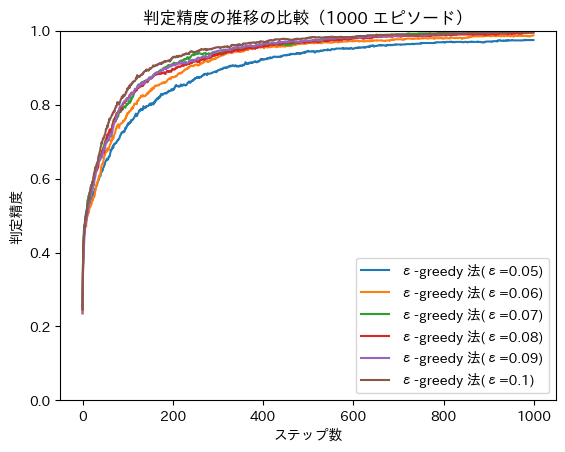

In [18]:
MAB_Agent.compare_accuracy_by_step(egreedy_agents[5:11])

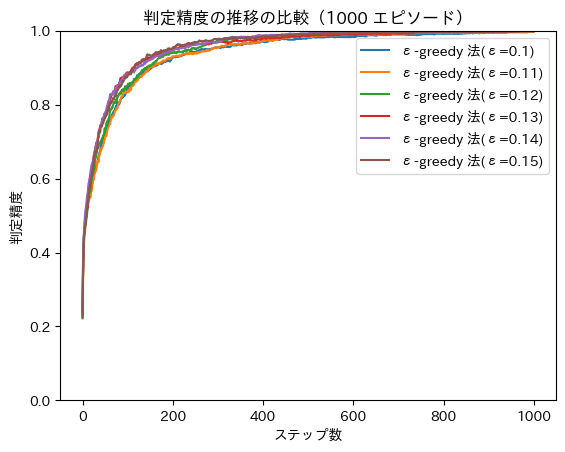

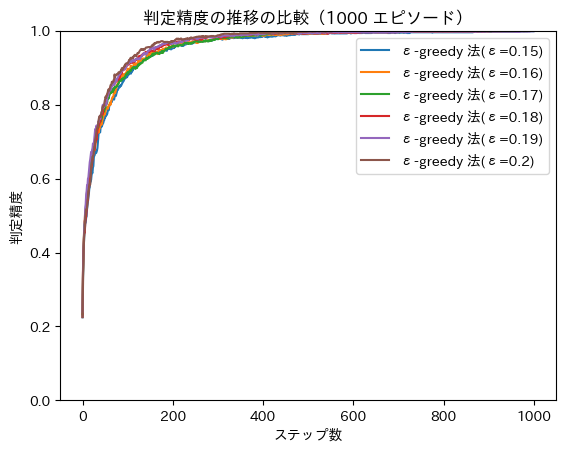

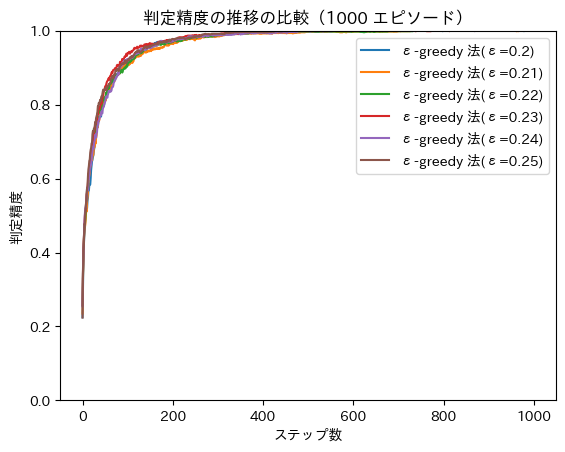

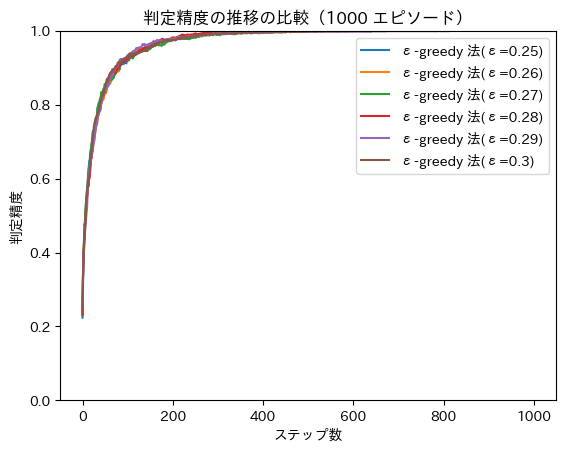

In [19]:
MAB_Agent.compare_accuracy_by_step(egreedy_agents[10:16])
MAB_Agent.compare_accuracy_by_step(egreedy_agents[15:21])
MAB_Agent.compare_accuracy_by_step(egreedy_agents[20:26])
MAB_Agent.compare_accuracy_by_step(egreedy_agents[25:])

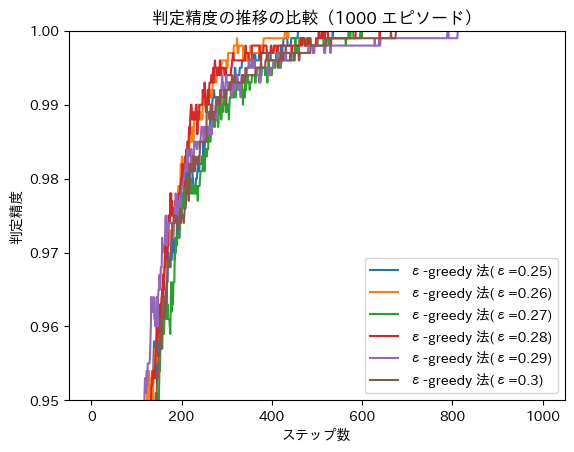

In [20]:
MAB_Agent.compare_accuracy_by_step(egreedy_agents[25:], miny=0.95)

In [21]:
@staticmethod
def draw_accuracy_of_best_agent_by_step(agent_list, miny=0, maxy=None):
    mean_mean_coins_by_step_list = [agent.mean_mean_coins_by_step for agent in agent_list]
    best_index = np.argmax(mean_mean_coins_by_step_list, axis=0)
    for agent in agent_list:
        agent.calc_accuracy_by_step()
    accuracy_of_best_hparam_by_step = []
    for step, index in enumerate(best_index):
        accuracy_of_best_hparam_by_step.append(agent_list[index].accuracy_by_step[step])
        
    plt.title(f"{agent_list[0].NAME}\n最適なエージェントにおける判定精度の推移（{agent_list[0].episodenum} エピソード）")
    plt.plot(accuracy_of_best_hparam_by_step)
    plt.ylim(miny, maxy)
    plt.xlabel("ステップ数")
    plt.ylabel("判定精度")
    plt.show() 
    
MAB_Agent.draw_accuracy_of_best_agent_by_step = draw_accuracy_of_best_agent_by_step

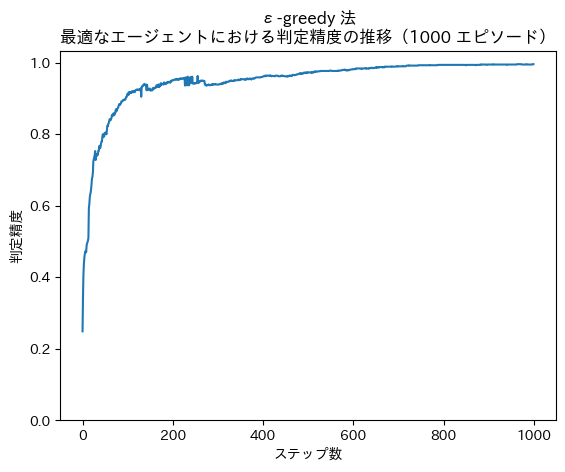

In [22]:
MAB_Agent.draw_accuracy_of_best_agent_by_step(egreedy_agents)

In [23]:
@staticmethod
def draw_accuracy_of_best_agent_by_step(agent_list, miny=0, maxy=None):
    mean_mean_coins_by_step_list = [agent.mean_mean_coins_by_step for agent in agent_list]
    best_index = np.argmax(mean_mean_coins_by_step_list, axis=0)
    for agent in agent_list:
        agent.calc_accuracy_by_step()
    accuracy_of_best_hparam_by_step = []
    for step, index in enumerate(best_index):
        accuracy_of_best_hparam_by_step.append(agent_list[index].accuracy_by_step[step])
        
    plt.title(f"{agent_list[0].NAME}\n最適なエージェントにおける判定精度の推移（{agent_list[0].episodenum} エピソード）")
    plt.plot(accuracy_of_best_hparam_by_step)
    plt.ylim(miny, maxy)
    plt.xlabel("ステップ数")
    plt.ylabel("判定精度")
    plt.show() 
    return accuracy_of_best_hparam_by_step
    
MAB_Agent.draw_accuracy_of_best_agent_by_step = draw_accuracy_of_best_agent_by_step

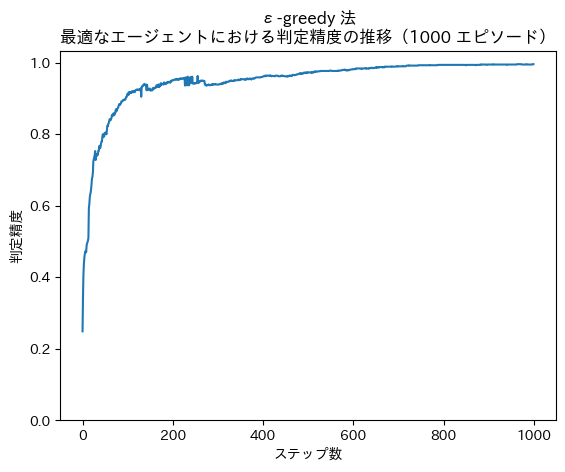

step 50: 0.802
step 100: 0.912
step 150: 0.923
step 200: 0.951
step 250: 0.942
step 300: 0.939
step 350: 0.954


In [24]:
accuracy_of_best_hparam_by_step = MAB_Agent.draw_accuracy_of_best_agent_by_step(egreedy_agents)

for step in range(50, 400, 50):
    print(f"step {step}: {accuracy_of_best_hparam_by_step[step]}")